In [1]:
import matplotlib
import torch
import torch.nn as nn
import torch.nn.functional as F
import ml_collections
import sys
import bookkeeping
import copy
import yaml

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "font.size": 16,          # base font size
})


## Load dataset

In [3]:
#from model import ResidualMLP, SequenceTransformer
#model_run  = './runs/run_20260505_100058' 
#model_run = './runs/run_20260505_121704'
#model_run = './runs/run_20260505_144134'
model_run = './runs/run_20260505_174215'

with open(model_run + "/config.yaml", "r") as f:
    cfg_dict = yaml.safe_load(f)
cfg = ml_collections.ConfigDict(cfg_dict)

# load data
data_folder = './data/'
train_data  = np.load(data_folder + 'train.npy')
test_data   = np.load(data_folder + 'test.npy')

# descramble data back to original ordering
descramble_key = np.loadtxt(data_folder + 'descramble_key.txt')
def descramble(samples):
    return descramble_key[samples.flatten()].reshape(*samples.shape)
descrambled_train_data  = descramble(train_data)
descrambled_test_data   = descramble(test_data)

mean_data = (descrambled_train_data / cfg.data.S).mean()
var_data  = (descrambled_train_data / cfg.data.S).var()

print('Size of descrambled_train_data:', descrambled_train_data.shape)
print('Size of descrambled_test_data:', descrambled_test_data.shape)

Size of descrambled_train_data: (6000, 256)
Size of descrambled_test_data: (973, 256)


## Train model

In [11]:
#from model import ResidualMLP, SequenceTransformer
#model_run  = './runs/run_20260505_100058' 
#model_run = './runs/run_20260505_121704'
#model_run = './runs/run_20260505_144134'
model_run = './runs/run_20260505_174215'

with open(model_run + "/config.yaml", "r") as f:
    cfg_dict = yaml.safe_load(f)
cfg = ml_collections.ConfigDict(cfg_dict)

class PoissonFolmerBase:
    def __init__(self, S, T0, T, dim):
        self.S    = S
        self.T0   = T0
        self.T    = T
        self.dim  = dim
        self.x0   = torch.zeros(1, self.dim).long() #0.0

    def sample_initial_cond(self, N):
        return torch.tile(self.x0, (N,1)) 
    
    def conditional_sample(self, t, XT):  # t: [B]
        # Sample from P[X_t = k|X_T = m]
        assert(XT.shape[1] == self.dim)
        assert(XT.shape[0] == len(t))
        return torch.distributions.binomial.Binomial(total_count=XT.T, probs=t/self.T).sample().long().T

# define forward process and model
forward = PoissonFolmerBase(S=cfg.data.S, T0=cfg.data.T0, T=cfg.data.T, dim=cfg.data.dim-cfg.data.condition_dim)

# define approximate model
# #from conditional_model import ConditionalSequenceTransformer
# #NNmodel = ConditionalSequenceTransformer(cfg, device)
# #NNmodel = NNmodel.to(device)

# import os
# _EDM_DIR = os.path.join('../', "edm")
# if _EDM_DIR not in os.sys.path:
#     os.sys.path.insert(0, _EDM_DIR)
# from training.networks import PFPrecond  

# # EDM model from edm/training/networks.py
# NNmodel = PFPrecond(
#     img_resolution=16,
#     img_channels=1,
#     label_dim=0,
#     use_fp16=False,
#     log_noise_eps=cfg.model.log_noise_eps,
#     mean_data=cfg.model.mean_data,
#     var_data=cfg.model.var_data,
#     cin_eps=cfg.model.cin_eps,
#     model_type="SongUNet",
#     model_channels=cfg.model.model_channels,
#     channel_mult=[1, 2, 2, 2],
#     num_blocks=2,
#     dropout=cfg.model.dropout,
# ).to(device)

from conditional_model_edm import ConditionalSequenceTransformer, PFConditionalPrecond
# build core model and wrap with PF preconditioning
core = ConditionalSequenceTransformer(cfg).to(device)
NNmodel = PFConditionalPrecond(
    core_model=core,
    log_noise_eps=cfg.model.log_noise_eps,
    mean_data=mean_data,
    var_data=var_data,
    cin_eps=cfg.model.cin_eps,
).to(device)
#NNmodel = nn.DataParallel(NNmodel).to(device)

for p in NNmodel.parameters():
    p.requires_grad_(False)  # EMA model is not trained by gradient

# load NN model
#model_run  = './runs/run_20260505_003655' 
model_path = Path(model_run + '/checkpoint.pt')
if model_path.exists():
    print('Loading model from', model_path)
    checkpoint = torch.load(model_path, map_location=device)
    print(checkpoint.keys())
    NNmodel.load_state_dict(checkpoint['ema_state_dict'])

# def vector_to_image(x):
#     # x: [B, 256] -> [B, 1, 16, 16]
#     return x.float().reshape(x.shape[0], 1, 16, 16)

# def image_to_vector(x):
#     # x: [B, 1, 16, 16] -> [B, 256]
#     return x.reshape(x.shape[0], -1)

# define intensity model
class Intensity(nn.Module):
    def __init__(self, model, max_time):
        super(Intensity, self).__init__()
        self.model = model
        self.max_time = max_time

    def forward(self, ctx, x, t):
        assert(t.ndim == 1)
        x_full = torch.cat([ctx, x], dim=1)
        sigma = -torch.log(t + cfg.model.log_noise_eps)
        #x_img = vector_to_image(x_full)
        #model_output = self.model(x_img, t)
        #model_output = image_to_vector(model_output)[:, cfg.data.condition_dim:]
        model_output = self.model(ctx, x, sigma) * cfg.data.S #, denormalize_output=True)
        return (model_output - x.float()) / (self.max_time - t[:,None])

NNintensity = Intensity(NNmodel, max_time=cfg.data.T)

n_params = 0
for p in NNmodel.parameters():
    n_params += p.numel()  # EMA model is not trained by gradient
print(f'Number of parameters in NN model: {n_params}')

Loading model from runs/run_20260505_174215/checkpoint.pt
dict_keys(['epoch', 'model_state_dict', 'ema_state_dict', 'optimizer_state_dict', 'loss', 'grad_norms'])
Number of parameters in NN model: 5094401


## Post-process

Text(0, 0.5, 'Gradient Norm')

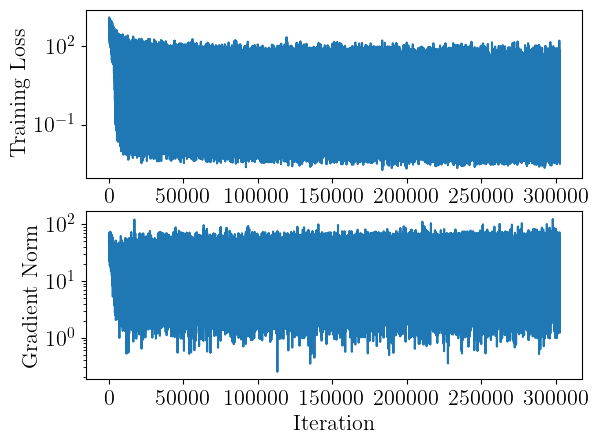

In [12]:
plt.figure()
plt.subplot(2,1,1)
plt.semilogy(checkpoint['loss'])
plt.xlabel('Iteration')
plt.ylabel('Training Loss')
plt.subplot(2,1,2)
plt.semilogy(checkpoint['grad_norms'])
plt.xlabel('Iteration')
plt.ylabel('Gradient Norm')

## Generate conditional samples

In [13]:
from sampling import TauLeaping, Euler
#cfg.sampling.ode_solver = 'tau-leaping'
cfg.sampling.ode_solver = 'euler'
num_samples = 2

# -------------- Sample the model ------------------
for test_data_idx in [10,12,14,16]:
    # plot sample
    plt.figure(figsize=(5,3))
    plt.scatter(np.arange(256)/16, descrambled_test_data[test_data_idx, :], alpha=0.5, label='Ground truth song')
    plt.axvline(x=2.0, color='black', linestyle='--', linewidth=2)
    plt.xlabel('Bar')
    plt.ylabel('Notes')
    plt.xlim(0,16)
    plt.grid()
    plt.title('Original', fontsize=14)
    #plt.legend()
    plt.tight_layout()
    file_name = model_run + '/sample_test' + str(test_data_idx) + '_truesong.pdf'
    plt.savefig(file_name, bbox_inches='tight')
    plt.close()
    # plot sample
    for k in range(num_samples):
        conditioner = torch.from_numpy(descrambled_test_data[test_data_idx, 0:cfg.data.condition_dim]).to(device).view(1, cfg.data.condition_dim)
        # define initial condition for sampling
        x0 = forward.sample_initial_cond(1)
        # define time grid and samples
        time_grid = torch.linspace(forward.T0, forward.T-cfg.sampling.early_stopping, cfg.sampling.num_steps)
        if cfg.sampling.ode_solver == 'euler':
            samples, x_hist = Euler(forward, conditioner, NNintensity, time_grid, x0, device=device)
        elif cfg.sampling.ode_solver == 'tau-leaping':
            samples, x_hist = TauLeaping(forward, conditioner, NNintensity, time_grid, x0, device=device, corrector_steps=2)
        else:
            raise ValueError('Sampler not recognized')
        samples = torch.cat((conditioner.cpu(), samples), dim=1)
        plt.figure(figsize=(5,3))
        #plt.scatter(np.arange(256), descrambled_test_data[test_data_idx, :], alpha=0.5, label='Ground truth song')
        plt.scatter(np.arange(256)/16, samples.cpu().numpy(), alpha=0.5, label='Generated sample')
        plt.axvline(x=2.0, color='black', linestyle='--', linewidth=2)
        plt.xlabel('Bar')
        plt.ylabel('Notes')
        plt.xlim(0,16)
        plt.grid()
        plt.title('Sample '+str(k), fontsize=14)
        #plt.legend()
        plt.tight_layout()
        file_name = model_run + '/sample_test' + str(test_data_idx) + '_rand' + str(k) + '.pdf'
        plt.savefig(file_name, bbox_inches='tight')
        plt.close()

## Compute metrics

KeyboardInterrupt: 

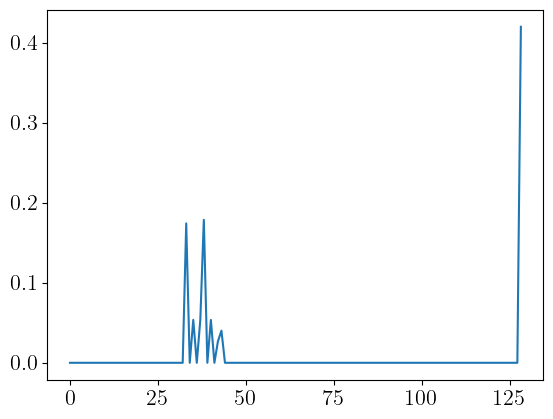

In [ ]:
def hellinger_distance(p, q):
    """Compute the Hellinger distance between two discrete distributions p and q."""
    return torch.sqrt(0.5 * torch.sum((torch.sqrt(p) - torch.sqrt(q)) ** 2))

# time grid for sampling
time_grid = torch.linspace(forward.T0, forward.T, cfg.sampling.num_steps)
num_samples = 5

for test_data_idx in [10]: #[10,12]:

    conditioner = torch.from_numpy(descrambled_test_data[test_data_idx, 0:cfg.data.condition_dim]).to(device).view(1, cfg.data.condition_dim)
    conditioner = torch.tile(conditioner, (num_samples, 1))

    # extract true sample and compute empirical distribution
    true_samples = descrambled_test_data[test_data_idx, cfg.data.condition_dim:]
    true_samples = torch.from_numpy(true_samples).long()
    empirical_dist_q = torch.from_numpy(np.bincount(true_samples.flatten(), minlength=forward.S)).float()
    empirical_dist_q = empirical_dist_q / empirical_dist_q.sum()  # normalize to get probabilities
    plt.figure()
    plt.plot(empirical_dist_q.numpy(), label='Generated')

    # generate samples
    x0 = forward.sample_initial_cond(num_samples)
    samples, x_hist = TauLeaping(forward, conditioner, NNintensity, time_grid, x0, device=device, corrector_steps=2) #Euler(forward, conditioner, NNintensity, time_grid, x0, device=device)

    # compute distances
    distances = torch.zeros((num_samples,))
    for k in range(num_samples):
        gen_samples_k = samples[k, cfg.data.condition_dim:].long()
        empirical_dist_p = torch.from_numpy(np.bincount(gen_samples_k.flatten(), minlength=forward.S)).float()
        empirical_dist_p = empirical_dist_p / empirical_dist_p.sum()  # normalize to get probabilities
        # compute hellinger distance
        distances[k] = hellinger_distance(empirical_dist_p, empirical_dist_q)
        # plot sample
        plt.plot(empirical_dist_p.numpy(), '--', label=f'Sample {k}')
    plt.xlabel('State')
    plt.ylabel('Frequency')
    plt.legend()
    plt.show()

    print(f"Avg Hellinger distance for test data index {test_data_idx}: {distances.mean():.4f} pm {distances.std():.4f}")

